<a href="https://colab.research.google.com/github/AndresAvella09/Proyecto_Multimodal/blob/main/notebooks/12_buscador_recientes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 12 · Buscador: películas de 2020 a 2026

El buscador de los notebooks 09-11 solo conoce películas de MM-IMDB (hasta ~2016). Aquí se le agregan las
**3 000 películas recientes de TMDB** del notebook 07 y se mide si **busca igual de bien con películas nuevas**.
Es la misma pregunta del notebook 08 (¿cambia el desbalance entre modalidades con la época?), ahora en la búsqueda.

**Sin entrenar nada nuevo:** las películas de TMDB pasan por los mismos codificadores (CLIP para el póster, ya
calculado en el 07; E5 para la sinopsis, aquí) y por **los mismos adaptadores del notebook 11**, entrenados solo
con películas de MM-IMDB. Si el adaptador aprendió "qué es el terror" y no "qué películas viejas son de terror",
debería servir igual con las nuevas.

**Tres grupos, dos efectos** (los mismos del 08):

| Grupo | Películas | Póster y sinopsis de |
|---|---|---|
| `control_mmimdb` | ~1 500 películas del test de MM-IMDB | MM-IMDB |
| `control_tmdb` | **las mismas** películas | TMDB |
| `recientes_tmdb` | 3 000 películas de 2020-2026 | TMDB |

- **Efecto de la fuente** = `control_tmdb − control_mmimdb`: mismas películas, cambia de dónde salen póster y sinopsis.
- **Efecto de la época** = `recientes_tmdb − control_tmdb`: misma fuente, otra época.

| Sección | Qué hace | Guarda |
|---|---|---|
| 1 | Vectores de TMDB: E5 de las sinopsis (**GPU recomendada**, ~3 min) | `embeddings/tmdb_e5_txt.npy` |
| 2 | Aplica los adaptadores del 11 y hace las miniaturas de los pósters | `tmdb_*_adapt.npy`, `data/tmdb_posters_mini.parquet` |
| 3 | Evaluación por grupo con las 88 búsquedas del notebook 10 | `resultados/recientes_*.csv` |
| 4 | ¿Cambia el mejor peso del póster con la época? | `resultados/recientes_alfa.csv` |
| 5 | Por género | `resultados/recientes_por_genero.csv` |
| 6 | Catálogo mezclado (el de la app): ¿las recientes salen con justicia? Elige cómo corregirlo | `resultados/recientes_sesgo.csv` |

**Requisitos (todo en la misma carpeta de Drive):** notebooks 05, 07, 09, 10 y 11.

In [5]:
import os, sys, io, re, json, time, subprocess
EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'sentence-transformers'], check=True)

REPO = '/content/Proyecto_Multimodal'
if os.path.exists(REPO):
    subprocess.run(['git', '-C', REPO, 'pull', '-q'], check=True)
else:
    subprocess.run(['git', 'clone', '-q', 'https://github.com/AndresAvella09/Proyecto_Multimodal.git', REPO], check=True)
sys.path.insert(0, REPO)

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image
from src.buscador import (MODELO_POSTER, MODELO_SINOPSIS, CONSULTAS, TIPOS, l2, zscore, puntajes,
                          cargar_adaptador, adaptar, ap_por_consulta, precision_en_k)

BASE = os.environ.get('PM_BASE', '/content/drive/MyDrive/proyecto_multimodal')
DATA, EMB, RES, MOD = f'{BASE}/data', f'{BASE}/embeddings', f'{BASE}/resultados', f'{BASE}/modelos'
if not os.path.exists(f'{EMB}/clip_img.npy') and os.path.exists(f'{EMB}/embeddings/clip_img.npy'):
    EMB = f'{EMB}/embeddings'
os.makedirs(RES, exist_ok=True)

NECESARIOS = {f'{DATA}/mmimdb_con_anio.parquet': '05', f'{DATA}/tmdb_meta.parquet': '07',
              f'{DATA}/tmdb/posters': '07', f'{EMB}/tmdb_clip_img.npy': '07', f'{DATA}/posters_mini.parquet': '09',
              f'{EMB}/clip_img.npy': '03', f'{EMB}/e5_txt.npy': '10', f'{MOD}/adaptador_poster_s0.pt': '11',
              f'{MOD}/adaptador_sinopsis_s0.pt': '11'}
faltan = {r: nb for r, nb in NECESARIOS.items() if not os.path.exists(r)}
assert not faltan, ('Faltan archivos (¿están los resultados de los dos en la misma carpeta de Drive?):\n'
                    + '\n'.join(f'  {r}  (notebook {nb})' for r, nb in faltan.items()))

SEED, B, R_SUB, MIN_POS = 42, 2000, 20, 20
ALFA = 0.5            # peso del póster en 'ambos' (el de la evaluación de los notebooks 10 y 11)
ALFA_APP = 0.4        # el que usa la app
K_SESGO = 50
device = 'cuda' if torch.cuda.is_available() else 'cpu'
rng = np.random.default_rng(SEED)

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'figure.dpi': 110})
GRUPOS = ['control_mmimdb', 'control_tmdb', 'recientes_tmdb']
COL_GRUPO = {'control_mmimdb': '#2563eb', 'control_tmdb': '#10b981', 'recientes_tmdb': '#ea580c'}
MODOS = ['poster', 'sinopsis', 'ambos']
print('Vectores en', EMB, '| dispositivo', device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Vectores en /content/drive/MyDrive/proyecto_multimodal/embeddings | dispositivo cuda


## 1. Vectores de las películas de TMDB

- **Póster:** `tmdb_clip_img.npy` del notebook 07 (mismo preprocesamiento que MM-IMDB, verificado allí).
- **Sinopsis:** E5 con el prefijo `passage: `, igual que en el notebook 10. Se usa la sinopsis **normalizada** del
  07 (minúsculas, números como `N`), que tiene el mismo estilo que las de MM-IMDB: así E5 ve los dos grupos igual.

In [6]:
pelis = pd.read_parquet(f'{DATA}/mmimdb_con_anio.parquet')
assert (pelis['fila_hdf5'].values == np.arange(len(pelis))).all()
GENEROS = [c[4:] for c in pelis.columns if c.startswith('hoy_')]
Y_mm = pelis[[f'hoy_{g}' for g in GENEROS]].values.astype(np.float32)
es_cine = pelis['es_pelicula'].fillna(False).values.astype(bool)

tm = pd.read_parquet(f'{DATA}/tmdb_meta.parquet')
Y_tm = tm[[f'hoy_{g}' for g in GENEROS]].values.astype(np.float32)
i_ctrl = np.where(tm['grupo'] == 'control')[0]
i_rec = np.where(tm['grupo'] == 'reciente')[0]
filas_ctrl = tm['fila_hdf5'].values[i_ctrl]

from sentence_transformers import SentenceTransformer
modelo_clip = SentenceTransformer(MODELO_POSTER, device=device)
modelo_e5 = SentenceTransformer(MODELO_SINOPSIS, device=device)
modelo_e5.max_seq_length = 512
if device == 'cuda':
    modelo_e5.half()

def codificar_clip(textos):
    return l2(modelo_clip.encode(list(textos), convert_to_numpy=True))

def codificar_e5(textos, tipo='query', **kw):
    return modelo_e5.encode([f'{tipo}: {t}' for t in textos], convert_to_numpy=True,
                            normalize_embeddings=True, **kw).astype(np.float32)

RUTA_E5 = f'{EMB}/tmdb_e5_txt.npy'
if os.path.exists(RUTA_E5):
    e5_tm = np.load(RUTA_E5)
    print('E5 de TMDB cargado de Drive:', e5_tm.shape)
else:
    t0 = time.time()
    e5_tm = codificar_e5(tm['sinopsis'].fillna('').tolist(), 'passage', batch_size=64, show_progress_bar=True)
    np.save(RUTA_E5, e5_tm)
    print(f'E5 de TMDB calculado en {time.time() - t0:.0f} s y guardado:', e5_tm.shape)

V_mm = {'poster': l2(np.load(f'{EMB}/clip_img.npy')), 'sinopsis': l2(np.load(f'{EMB}/e5_txt.npy'))}
V_tm = {'poster': l2(np.load(f'{EMB}/tmdb_clip_img.npy')), 'sinopsis': l2(e5_tm)}
assert all(len(v) == len(pelis) for v in V_mm.values()) and all(len(v) == len(tm) for v in V_tm.values())

print(f'\nControl, misma película en MM-IMDB y en TMDB (similitud coseno):')
for m in V_mm:
    cos = (V_mm[m][filas_ctrl] * V_tm[m][i_ctrl]).sum(1)
    print(f'  {m:9s} mediana {np.median(cos):.3f} | p10 {np.percentile(cos, 10):.3f}')

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

E5 de TMDB cargado de Drive: (4493, 768)

Control, misma película en MM-IMDB y en TMDB (similitud coseno):
  poster    mediana 0.754 | p10 0.551
  sinopsis  mediana 0.890 | p10 0.835


## 2. Adaptadores del notebook 11 y miniaturas

Se cargan los pesos guardados en `modelos/` y se aplican **sin reentrenar**. Primero se comprueba que, aplicados
a MM-IMDB, reproducen los vectores adaptados que guardó el 11.

In [7]:
SEMILLAS = sorted(int(re.search(r'_s(\d+)\.pt$', f).group(1)) for f in os.listdir(MOD)
                  if re.match(r'adaptador_poster_s\d+\.pt$', f)
                  and os.path.exists(f"{MOD}/{f.replace('poster', 'sinopsis')}"))
ADAPT = {(m, s): cargar_adaptador(f'{MOD}/adaptador_{m}_s{s}.pt', V_mm[m].shape[1], len(GENEROS))
         for m in V_mm for s in SEMILLAS}
print('Semillas de adaptador:', SEMILLAS)

muestra = rng.choice(len(pelis), 2000, replace=False)
for m, archivo in [('poster', 'poster_adapt.npy'), ('sinopsis', 'e5_adapt.npy')]:
    if os.path.exists(f'{EMB}/{archivo}'):
        ref = l2(np.load(f'{EMB}/{archivo}')[muestra])
        cos = (adaptar(ADAPT[(m, 0)], V_mm[m][muestra]) * ref).sum(1)
        print(f'Reproducción del 11 ({m}): cos mín {cos.min():.4f}')
        assert cos.min() > 0.99, f'el adaptador de {m} no reproduce {archivo}'

VA_mm = {(m, s): adaptar(ADAPT[(m, s)], V_mm[m]) for m in V_mm for s in SEMILLAS}
VA_tm = {(m, s): adaptar(ADAPT[(m, s)], V_tm[m]) for m in V_tm for s in SEMILLAS}
for m in V_tm:
    c_mm = np.mean([(VA_mm[(m, s)] * V_mm[m]).sum(1).mean() for s in SEMILLAS])
    c_tm = np.mean([(VA_tm[(m, s)][i_rec] * V_tm[m][i_rec]).sum(1).mean() for s in SEMILLAS])
    print(f'{m:9s} cuánto mueve el adaptador (cos con el original): MM-IMDB {c_mm:.3f} | recientes {c_tm:.3f}')

Semillas de adaptador: [0, 1, 2]
Reproducción del 11 (poster): cos mín 1.0000
Reproducción del 11 (sinopsis): cos mín 1.0000
poster    cuánto mueve el adaptador (cos con el original): MM-IMDB 0.765 | recientes 0.794
sinopsis  cuánto mueve el adaptador (cos con el original): MM-IMDB 0.288 | recientes 0.304


In [8]:
RUTA_MINI = f'{DATA}/tmdb_posters_mini.parquet'
TAM_MINI = (120, 192)   # igual que posters_mini.parquet del notebook 09

def a_mini(ruta):
    buf = io.BytesIO()
    if os.path.exists(ruta):
        img = Image.open(ruta).convert('RGB').resize(TAM_MINI, Image.LANCZOS)
    else:
        img = Image.new('RGB', TAM_MINI, (40, 40, 40))
    img.save(buf, format='JPEG', quality=82)
    return buf.getvalue()

if os.path.exists(RUTA_MINI):
    mini_tm = pd.read_parquet(RUTA_MINI)
else:
    mini_tm = pd.DataFrame({'tconst': tm['tconst'],
                            'jpg': [a_mini(f'{DATA}/tmdb/posters/{t}.jpg') for t in tm['tconst']]})
    mini_tm.to_parquet(RUTA_MINI, index=False)
assert (mini_tm['tconst'].values == tm['tconst'].values).all()
JPG_TM = mini_tm['jpg'].tolist()
JPG_MM = pd.read_parquet(f'{DATA}/posters_mini.parquet')['jpg'].tolist()
print(f'Miniaturas de TMDB: {len(JPG_TM):,}')

Miniaturas de TMDB: 4,493


## 3. ¿Busca igual de bien con películas nuevas?

Las **88 búsquedas de género del notebook 10** (frase y palabra, español e inglés) se hacen **dentro de cada
grupo**: el catálogo son solo las películas de ese grupo.

**Dos cuidados para comparar grupos:**
- **Mismo tamaño de catálogo.** Las recientes son el doble que el control. Se toman `R_SUB` submuestras de las
  recientes del tamaño del control y se promedia.
- **Distinta mezcla de géneros.** El AP de un orden al azar es la proporción de películas del género, y esa
  proporción cambia entre épocas (en el 08: Action +15 puntos). Por eso además del mAP se reporta la
  **ganancia sobre el azar** (AP − proporción del género).

El IC 95% es por **bootstrap sobre géneros**, como en los notebooks 10 y 11 (cada género = promedio de sus 4
búsquedas). Las diferencias entre grupos son **pareadas por género**.

In [9]:
# Solo películas de cine en el control (como el catálogo de los notebooks 10 y 11)
sel_c = es_cine[filas_ctrl]
IDX_G = {'control_mmimdb': ('mm', filas_ctrl[sel_c]), 'control_tmdb': ('tm', i_ctrl[sel_c]),
         'recientes_tmdb': ('tm', i_rec)}
Y_G = {g: (Y_mm if f == 'mm' else Y_tm)[idx] for g, (f, idx) in IDX_G.items()}
n_ctrl, n_rec = len(Y_G['control_tmdb']), len(Y_G['recientes_tmdb'])

pos_c, pos_r = Y_G['control_tmdb'].sum(0), Y_G['recientes_tmdb'].sum(0) * n_ctrl / n_rec
GEN_EVAL = [g for k, g in enumerate(GENEROS) if g in CONSULTAS and pos_c[k] >= MIN_POS and pos_r[k] >= MIN_POS]
print(f'Catálogos: control {n_ctrl:,} | recientes {n_rec:,} (submuestras de {n_ctrl:,})')
print(f'Géneros evaluados: {len(GEN_EVAL)} | fuera: {[g for g in GENEROS if g not in GEN_EVAL]}')

consultas = pd.DataFrame([{'genero': g, 'idioma': i, 'tipo': t, 'texto': CONSULTAS[g][k]}
                          for g in GEN_EVAL for k, (i, t) in enumerate(TIPOS)])
gi = np.array([GENEROS.index(g) for g in consultas['genero']])
Q = {'poster': codificar_clip(consultas['texto']), 'sinopsis': codificar_e5(consultas['texto'], 'query')}
SUB = [rng.choice(n_rec, n_ctrl, replace=False) for _ in range(R_SUB)]

def vectores(g, m, version):
    # version: 'antes' (sin adaptar) o una semilla del adaptador
    fuente, idx = IDX_G[g]
    if version == 'antes':
        return (V_mm if fuente == 'mm' else V_tm)[m][idx]
    return (VA_mm if fuente == 'mm' else VA_tm)[(m, version)][idx]

def evaluar(g, version, modo, alfa=ALFA):
    # Métricas por búsqueda (promedio de submuestras en las recientes)
    Vp, Vs, Y = vectores(g, 'poster', version), vectores(g, 'sinopsis', version), Y_G[g][:, gi]
    out = []
    for r in (SUB if g == 'recientes_tmdb' else [slice(None)]):
        S = puntajes(Q['poster'], Q['sinopsis'], Vp[r], Vs[r], modo, alfa)
        out.append([ap_por_consulta(Y[r], S), precision_en_k(Y[r], S), Y[r].mean(0)])
    ap, p10, azar = np.mean(out, axis=0)
    return {'AP': ap, 'p@10': p10, 'azar': azar}

t0 = time.time()
filas = []
for g in GRUPOS:
    for modo in MODOS:
        for etapa, versiones in [('antes', ['antes']), ('después', SEMILLAS)]:
            r = [evaluar(g, v, modo) for v in versiones]
            d = consultas.copy()
            for k in ['AP', 'p@10', 'azar']:
                d[k] = np.mean([x[k] for x in r], axis=0)
            d['grupo'], d['modo'], d['etapa'] = g, modo, etapa
            filas.append(d)
por_consulta = pd.concat(filas, ignore_index=True)
por_consulta['sobre_azar'] = por_consulta['AP'] - por_consulta['azar']
por_gen = por_consulta.groupby(['grupo', 'modo', 'etapa', 'genero'])[['AP', 'p@10', 'azar', 'sobre_azar']].mean()
print(f'Evaluación: {time.time() - t0:.0f} s')

Catálogos: control 1,496 | recientes 2,997 (submuestras de 1,496)
Géneros evaluados: 18 | fuera: ['War', 'Musical', 'Western', 'Short', 'Film-Noir']
Evaluación: 7 s


In [10]:
def ic_generos(x):
    medias = rng.choice(x, size=(B, len(x)), replace=True).mean(axis=1)
    return x.mean(), *np.percentile(medias, [2.5, 97.5])

def serie(g, modo, etapa, col='AP'):
    return por_gen.loc[(g, modo, etapa), col].loc[GEN_EVAL].values

filas = []
for g in GRUPOS:
    for modo in MODOS:
        for etapa in ['antes', 'después']:
            f = {'grupo': g, 'modo': modo, 'etapa': etapa}
            for col, nombre in [('AP', 'mAP'), ('p@10', 'p@10'), ('azar', 'azar'), ('sobre_azar', 'sobre_azar')]:
                f[nombre], f[f'{nombre}_inf'], f[f'{nombre}_sup'] = ic_generos(serie(g, modo, etapa, col))
            filas.append(f)
resumen = pd.DataFrame(filas)
vista = resumen.assign(mAP=lambda d: d.apply(lambda r: f"{r.mAP:.3f} [{r.mAP_inf:.3f}, {r.mAP_sup:.3f}]", axis=1))
print('mAP por grupo (IC 95% bootstrap sobre géneros):')
vista.pivot_table(index=['modo', 'etapa'], columns='grupo', values='mAP', aggfunc='first')[GRUPOS]

mAP por grupo (IC 95% bootstrap sobre géneros):


grupo                   control_mmimdb          control_tmdb  \
modo     etapa                                                 
ambos    antes    0.308 [0.243, 0.381]  0.306 [0.241, 0.378]   
         después  0.552 [0.471, 0.632]  0.556 [0.470, 0.632]   
poster   antes    0.241 [0.173, 0.318]  0.236 [0.171, 0.313]   
         después  0.413 [0.324, 0.516]  0.410 [0.326, 0.503]   
sinopsis antes    0.254 [0.191, 0.322]  0.266 [0.209, 0.331]   
         después  0.486 [0.404, 0.565]  0.483 [0.407, 0.554]   

grupo                   recientes_tmdb  
modo     etapa                          
ambos    antes    0.355 [0.289, 0.418]  
         después  0.565 [0.482, 0.649]  
poster   antes    0.265 [0.194, 0.339]  
         después  0.426 [0.331, 0.528]  
sinopsis antes    0.316 [0.247, 0.379]  
         después  0.513 [0.431, 0.593]

In [11]:
# Diferencias pareadas por género: fuente, época y transferencia del adaptador
COMPARACIONES = {'fuente (control_tmdb − control_mmimdb)': ('control_tmdb', 'control_mmimdb'),
                 'época (recientes_tmdb − control_tmdb)': ('recientes_tmdb', 'control_tmdb')}
filas = []
for col in ['AP', 'sobre_azar']:
    for modo in MODOS:
        for etapa in ['antes', 'después']:
            for nombre, (a, b) in COMPARACIONES.items():
                d = serie(a, modo, etapa, col) - serie(b, modo, etapa, col)
                m, lo, hi = ic_generos(d)
                filas.append({'medida': col, 'modo': modo, 'etapa': etapa, 'comparacion': nombre,
                              'diferencia': m, 'ic_inf': lo, 'ic_sup': hi, 'generos_que_suben': int((d > 0).sum())})
        for g in GRUPOS:   # ganancia del adaptador en cada grupo
            d = serie(g, modo, 'después', col) - serie(g, modo, 'antes', col)
            m, lo, hi = ic_generos(d)
            filas.append({'medida': col, 'modo': modo, 'etapa': 'después − antes', 'comparacion': f'adaptador en {g}',
                          'diferencia': m, 'ic_inf': lo, 'ic_sup': hi, 'generos_que_suben': int((d > 0).sum())})
comparaciones = pd.DataFrame(filas)
comparaciones['sin_cero'] = (comparaciones['ic_inf'] > 0) | (comparaciones['ic_sup'] < 0)
fmt = lambda r: f"{r.diferencia:+.3f} [{r.ic_inf:+.3f}, {r.ic_sup:+.3f}]{' *' if r.sin_cero else ''}"
(comparaciones[comparaciones['medida'] == 'AP'].assign(valor=lambda d: d.apply(fmt, axis=1))
 .pivot_table(index=['comparacion', 'etapa'], columns='modo', values='valor', aggfunc='first')[MODOS])

modo                                                                       poster  \
comparacion                            etapa                                        
adaptador en control_mmimdb            después − antes  +0.172 [+0.135, +0.212] *   
adaptador en control_tmdb              después − antes  +0.174 [+0.140, +0.211] *   
adaptador en recientes_tmdb            después − antes  +0.160 [+0.124, +0.199] *   
fuente (control_tmdb − control_mmimdb) antes              -0.005 [-0.015, +0.005]   
                                       después            -0.003 [-0.017, +0.012]   
época (recientes_tmdb − control_tmdb)  antes              +0.029 [-0.003, +0.062]   
                                       después            +0.016 [-0.016, +0.045]   

modo                                                                     sinopsis  \
comparacion                            etapa                                        
adaptador en control_mmimdb            después − antes  +0.233 [+0.196, +0.272] *   
adaptador en control_tmdb              después − antes  +0.217 [+0.187, +0.250] *   
adaptador en recientes_tmdb            después − antes  +0.197 [+0.164, +0.232] *   
fuente (control_tmdb − control_mmimdb) antes            +0.012 [+0.002, +0.024] *   
                                       después            -0.003 [-0.019, +0.012]   
época (recientes_tmdb − control_tmdb)  antes            +0.051 [+0.026, +0.077] *   
                                       después            +0.030 [-0.007, +0.070]   

modo                                                                        ambos  
comparacion                            etapa                                       
adaptador en control_mmimdb            después − antes  +0.243 [+0.203, +0.289] *  
adaptador en control_tmdb              después − antes  +0.250 [+0.211, +0.295] *  
adaptador en recientes_tmdb            después − antes  +0.210 [+0.174, +0.248] *  
fuente (control_tmdb − control_mmimdb) antes              -0.002 [-0.016, +0.011]  
                                       después            +0.005 [-0.010, +0.019]  
época (recientes_tmdb − control_tmdb)  antes            +0.048 [+0.019, +0.078] *  
                                       después            +0.009 [-0.026, +0.042]

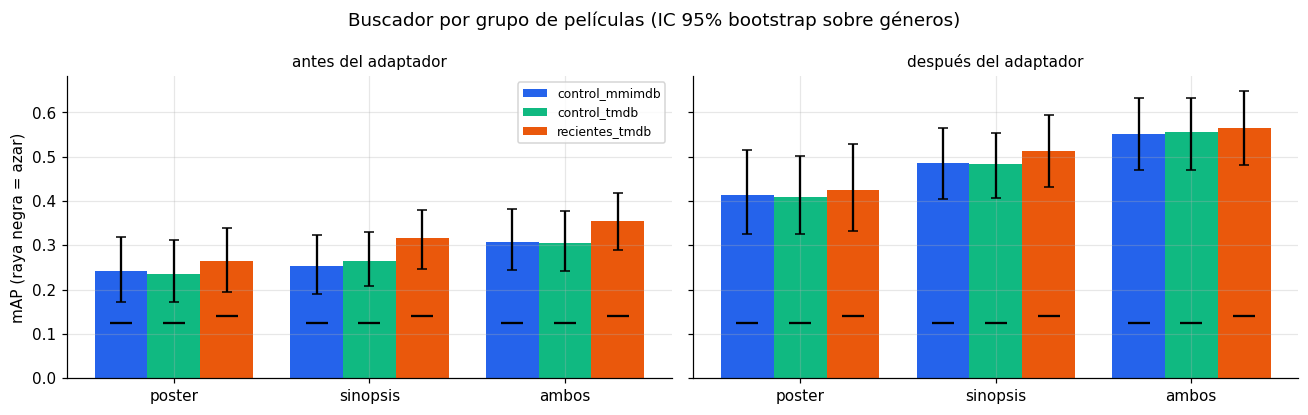

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
x = np.arange(len(MODOS))
for ax, etapa in zip(axes, ['antes', 'después']):
    for k, g in enumerate(GRUPOS):
        d = resumen[(resumen.grupo == g) & (resumen.etapa == etapa)].set_index('modo').loc[MODOS]
        ax.bar(x + (k - 1) * 0.27, d['mAP'], width=0.27, color=COL_GRUPO[g], label=g,
               yerr=[d['mAP'] - d['mAP_inf'], d['mAP_sup'] - d['mAP']], capsize=3)
        ax.scatter(x + (k - 1) * 0.27, d['azar'], marker='_', s=200, color='black', zorder=3)
    ax.set_xticks(x, MODOS); ax.set_title(f'{etapa} del adaptador', fontsize=10)
axes[0].set_ylabel('mAP (raya negra = azar)'); axes[0].legend(fontsize=8)
fig.suptitle('Buscador por grupo de películas (IC 95% bootstrap sobre géneros)')
plt.tight_layout(); plt.show()

**Cómo leer:**
- **Época** con IC sin el 0 en `sinopsis` pero no en `poster`: la sinopsis envejece peor también en la búsqueda,
  como en la clasificación del 08.
- **Adaptador en recientes** con mejora parecida a la de los controles: el adaptador aprendió los géneros, no las
  películas viejas. Si mejora mucho menos, se especializó en MM-IMDB.
- Si la época cambia el mAP pero no la **ganancia sobre el azar**, la diferencia viene de la mezcla de géneros.

## 4. ¿Cambia el mejor peso del póster con la época?

En el notebook 10 el mejor `alfa` (peso del póster en el modo `ambos`) fue 0.5, y 0.4 después de adaptar (11).
Si en las recientes el mejor `alfa` sube, el buscador debería **apoyarse más en el póster** con películas
nuevas: el mismo resultado que dio el índice de dependencia en la clasificación (0.20 → 0.27 en el 08).

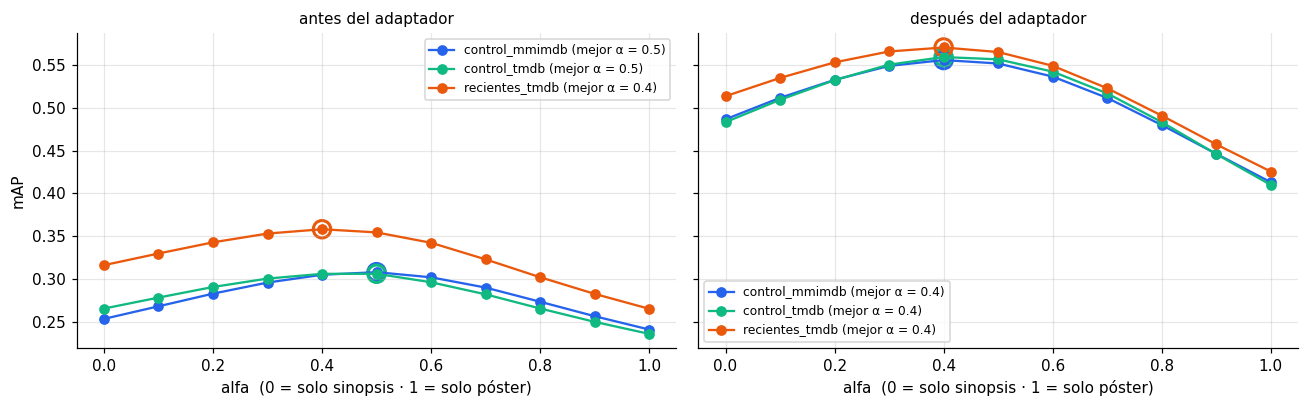

,,alfa,mAP
etapa,grupo,,
antes,control_mmimdb,0.5,0.308
después,control_mmimdb,0.4,0.556
antes,control_tmdb,0.5,0.306
después,control_tmdb,0.4,0.559
antes,recientes_tmdb,0.4,0.358
después,recientes_tmdb,0.4,0.570


In [13]:
ALFAS = np.round(np.arange(0, 1.01, 0.1), 1)
filas = []
for g in GRUPOS:
    for etapa, versiones in [('antes', ['antes']), ('después', SEMILLAS)]:
        for a in ALFAS:
            ap = np.mean([evaluar(g, v, 'ambos', a)['AP'] for v in versiones], axis=0)
            filas.append({'grupo': g, 'etapa': etapa, 'alfa': a,
                          'mAP': pd.Series(ap).groupby(consultas['genero'].values).mean().loc[GEN_EVAL].mean()})
barrido = pd.DataFrame(filas)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, etapa in zip(axes, ['antes', 'después']):
    for g in GRUPOS:
        d = barrido[(barrido.grupo == g) & (barrido.etapa == etapa)]
        mejor = d.loc[d['mAP'].idxmax()]
        ax.plot(d['alfa'], d['mAP'], marker='o', color=COL_GRUPO[g], label=f"{g} (mejor α = {mejor['alfa']:.1f})")
        ax.scatter([mejor['alfa']], [mejor['mAP']], s=130, facecolors='none', edgecolors=COL_GRUPO[g], lw=2)
    ax.set_xlabel('alfa  (0 = solo sinopsis · 1 = solo póster)'); ax.set_title(f'{etapa} del adaptador', fontsize=10)
    ax.legend(fontsize=8)
axes[0].set_ylabel('mAP')
plt.tight_layout(); plt.show()
mejores = barrido.loc[barrido.groupby(['grupo', 'etapa'])['mAP'].idxmax()].set_index(['etapa', 'grupo'])
mejores.round(3)

## 5. Por género: ¿qué se pierde con la época?

Cambio de AP entre el control y las recientes (ambos de TMDB), después del adaptador.

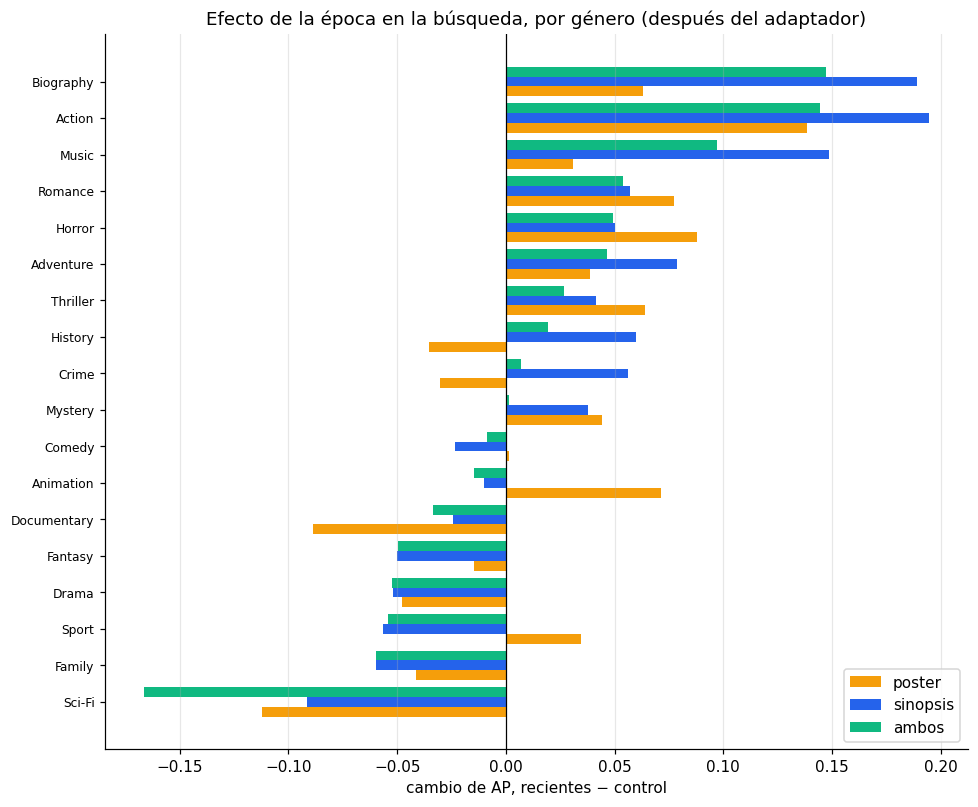

Correlación entre géneros: cambio de proporción vs cambio de AP (ambos): r = 0.41


In [14]:
por_genero = pd.DataFrame({f'cambio_{modo}': serie('recientes_tmdb', modo, 'después') - serie('control_tmdb', modo, 'después')
                           for modo in MODOS}, index=GEN_EVAL)
por_genero['cambio_azar'] = serie('recientes_tmdb', 'ambos', 'después', 'azar') - serie('control_tmdb', 'ambos', 'después', 'azar')
por_genero = por_genero.sort_values('cambio_ambos')

fig, ax = plt.subplots(figsize=(9, 0.33 * len(por_genero) + 1.5))
y = np.arange(len(por_genero))
COL_MOD = {'poster': '#f59e0b', 'sinopsis': '#2563eb', 'ambos': '#10b981'}
for k, modo in enumerate(MODOS):
    ax.barh(y + (k - 1) * 0.27, por_genero[f'cambio_{modo}'], height=0.27, color=COL_MOD[modo], label=modo)
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y, por_genero.index, fontsize=8); ax.grid(axis='y', visible=False)
ax.set_xlabel('cambio de AP, recientes − control'); ax.legend(loc='lower right')
ax.set_title('Efecto de la época en la búsqueda, por género (después del adaptador)')
plt.tight_layout(); plt.show()
r = np.corrcoef(por_genero['cambio_azar'], por_genero['cambio_ambos'])[0, 1]
print(f'Correlación entre géneros: cambio de proporción vs cambio de AP (ambos): r = {r:.2f}')

## 6. El catálogo de la app: películas viejas y nuevas juntas

En la app las recientes se suman al catálogo de MM-IMDB y los puntajes se estandarizan (z-score) **sobre todo el
catálogo**. Si los vectores de TMDB tienen otro nivel de similitud con las búsquedas (efecto de la fuente), las
recientes pueden salir de más o de menos **aunque no sean más relevantes**.

**Medida.** Para cada búsqueda, entre los `K_SESGO` primeros resultados:
- `cociente` = fracción de TMDB en el top / fracción de TMDB entre las películas relevantes. 1 = proporción justa.
- `cociente_irrelevantes` = lo mismo, **solo con los errores** (películas que no son del género): fracción de TMDB
  entre los errores del top / fracción de TMDB entre todas las no relevantes. Es la señal más limpia de sesgo: si
  las recientes aparecen de más **como errores**, el problema es la escala, no que sean mejores respuestas.

**Dos catálogos para separar las causas:**
- `fuente_pura`: el catálogo de MM-IMDB con las ~1 500 películas del **control** cambiadas por su versión de TMDB.
  Mismas películas y etiquetas: cualquier sesgo aquí es **solo de la fuente**.
- `app`: MM-IMDB + las recientes de TMDB, el catálogo real de la app (fuente + época).

**Tres formas de estandarizar** (`src.buscador.normalizar`):

| Corrección | Qué hace |
|---|---|
| `global` | z-score sobre todo el catálogo (lo que hacía la app) |
| `por_fuente` | z-score **dentro de cada fuente**, luego se mezclan |
| `por_fuente_media` | se resta la media de cada fuente y se divide por la desviación de todo el catálogo |

Se elige la que deja el `cociente_irrelevantes` más cerca de 1 en el catálogo `app` **sin bajar el mAP** del
catálogo más de 0.005. Se usa la representación adaptada (semilla 0) y el `alfa` de la app.

In [ ]:
from src.buscador import CORRECCIONES, puntajes_mixtos
s0 = SEMILLAS[0]
CAT_MM = np.where(es_cine)[0]
pos_ctrl = np.searchsorted(CAT_MM, filas_ctrl[sel_c])        # dónde está cada película del control en CAT_MM
assert (CAT_MM[pos_ctrl] == filas_ctrl[sel_c]).all()

def catalogo(nombre, version=s0):
    Vp, Vs = VA_mm[('poster', version)][CAT_MM].copy(), VA_mm[('sinopsis', version)][CAT_MM].copy()
    Y, fuente = Y_mm[CAT_MM].copy(), np.zeros(len(CAT_MM), bool)
    if nombre == 'fuente_pura':
        Vp[pos_ctrl] = VA_tm[('poster', version)][i_ctrl[sel_c]]
        Vs[pos_ctrl] = VA_tm[('sinopsis', version)][i_ctrl[sel_c]]
        fuente[pos_ctrl] = True
        return Vp, Vs, Y[:, gi], fuente
    return (np.concatenate([Vp, VA_tm[('poster', version)][i_rec]]), np.concatenate([Vs, VA_tm[('sinopsis', version)][i_rec]]),
            np.concatenate([Y, Y_tm[i_rec]])[:, gi], np.r_[fuente, np.ones(len(i_rec), bool)])

def medir_sesgo(Vp, Vs, Y, tmdb, modo, correccion):
    S = puntajes_mixtos(Q['poster'], Q['sinopsis'], Vp, Vs, tmdb, modo, ALFA_APP, correccion)
    top = np.argsort(-S, axis=1)[:, :K_SESGO]                          # (Q, K)
    rel_top = np.take_along_axis(Y.T, top, axis=1).astype(bool)        # ¿cada resultado del top es relevante?
    tm_top = tmdb[top]
    err = ~rel_top
    frac_err_top = np.where(err.sum(1) > 0, (tm_top & err).sum(1) / np.maximum(err.sum(1), 1), np.nan)
    frac_irr = ((1 - Y) * tmdb[:, None]).sum(0) / (1 - Y).sum(0)
    return {'frac_top': tm_top.mean(1), 'frac_relevantes': (Y * tmdb[:, None]).sum(0) / Y.sum(0),
            'cociente_irrelevantes': frac_err_top / frac_irr, 'ap': ap_por_consulta(Y, S)}

t0 = time.time()
filas = []
for nombre in ['fuente_pura', 'app']:
    Vp, Vs, Y, tmdb = catalogo(nombre)
    for correccion in CORRECCIONES:
        for modo in MODOS:
            d = consultas.copy()
            for k, v in medir_sesgo(Vp, Vs, Y, tmdb, modo, correccion).items():
                d[k] = v
            d['catalogo'], d['correccion'], d['modo'] = nombre, correccion, modo
            filas.append(d)
sesgo = pd.concat(filas, ignore_index=True)
sesgo['cociente'] = sesgo['frac_top'] / sesgo['frac_relevantes']
print(f'Catálogo app: {len(catalogo("app")[3]):,} películas, {catalogo("app")[3].mean():.1%} de TMDB | {time.time() - t0:.0f} s')

def resumir(d):
    g = d.groupby('genero')[['cociente', 'cociente_irrelevantes', 'ap']].mean().loc[GEN_EVAL]
    return pd.Series({'cociente': '{:.2f} [{:.2f}, {:.2f}]'.format(*ic_generos(g['cociente'].values)),
                      'cociente_irrelevantes': '{:.2f} [{:.2f}, {:.2f}]'.format(*ic_generos(g['cociente_irrelevantes'].dropna().values)),
                      'mAP': round(g['ap'].mean(), 4)})
tabla_sesgo = sesgo.groupby(['catalogo', 'modo', 'correccion']).apply(resumir)
tabla_sesgo

In [ ]:
# Elección de la corrección para la app (modo 'ambos', catálogo 'app')
d = (sesgo[(sesgo.catalogo == 'app') & (sesgo.modo == 'ambos')]
     .groupby(['correccion', 'genero'])[['cociente', 'cociente_irrelevantes', 'ap']].mean().groupby('correccion').mean())
# si en el top no hay errores (cociente_irrelevantes indefinido) se usa el cociente general
d['distancia_a_1'] = (d['cociente_irrelevantes'] - 1).abs().fillna((d['cociente'] - 1).abs())
ok = d[d['ap'] >= d.loc['global', 'ap'] - 0.005]
CORRECCION_APP = ok['distancia_a_1'].idxmin()
print(d.round(4).to_string())
print(f"\nCorrección elegida para la app: {CORRECCION_APP}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
COL_COR = {'global': '#9ca3af', 'por_fuente': '#7c3aed', 'por_fuente_media': '#db2777'}
for ax, nombre in zip(axes, ['fuente_pura', 'app']):
    x = np.arange(len(MODOS))
    for k, cor in enumerate(CORRECCIONES):
        v = [sesgo[(sesgo.catalogo == nombre) & (sesgo.modo == m) & (sesgo.correccion == cor)]
             .groupby('genero')['cociente_irrelevantes'].mean().mean() for m in MODOS]
        ax.bar(x + (k - 1) * 0.27, v, width=0.27, color=COL_COR[cor], label=cor)
    ax.axhline(1, color='black', lw=0.8); ax.set_xticks(x, MODOS)
    ax.set_title(f'catálogo {nombre}', fontsize=10)
axes[0].set_ylabel('TMDB entre los errores del top / esperado'); axes[0].legend(fontsize=8)
fig.suptitle('Sesgo hacia las películas de TMDB (1 = sin sesgo)')
plt.tight_layout(); plt.show()

In [ ]:
Vp_mix, Vs_mix, _, estreno = catalogo('app')

def mostrar_mixto(consulta, k=10, modo='ambos', correccion='global'):
    qp, qs = codificar_clip([consulta]), codificar_e5([consulta], 'query')
    s = puntajes_mixtos(qp, qs, Vp_mix, Vs_mix, estreno, modo, ALFA_APP, correccion)[0]
    top = np.argsort(-s)[:k]
    fig, axes = plt.subplots(1, k, figsize=(2.1 * k, 4.2))
    for ax, j in zip(axes, top):
        if estreno[j]:
            i = i_rec[j - len(CAT_MM)]
            img, tit, anio = JPG_TM[i], tm['titulo'].values[i], tm['anio'].values[i]
        else:
            i = CAT_MM[j]
            img, tit, anio = JPG_MM[i], pelis['titulo'].values[i], pelis['anio'].values[i]
        ax.imshow(Image.open(io.BytesIO(img))); ax.axis('off')
        tit = str(tit) if len(str(tit)) <= 22 else str(tit)[:20] + '…'
        anio = int(anio) if pd.notna(anio) else '?'
        ax.set_title(f"{'★ ' if estreno[j] else ''}{tit}\n({anio})", fontsize=8,
                     color='#ea580c' if estreno[j] else 'black')
    fig.suptitle(f'"{consulta}"  ·  {correccion}  ·  {estreno[top].sum()} de {k} son de 2020-2026 (★)', fontsize=11)
    plt.tight_layout(); plt.show()

for c in ['una película de superhéroes', 'una pandemia mundial', 'a robot in space', 'una casa embrujada en la nieve']:
    for cor in sorted({'global', CORRECCION_APP}):
        mostrar_mixto(c, correccion=cor)

## Guardado

- `embeddings/tmdb_e5_txt.npy`: E5 de las sinopsis de TMDB (sección 1).
- `embeddings/tmdb_poster_adapt.npy`, `embeddings/tmdb_e5_adapt.npy`: vectores adaptados (semilla 0, `float16`), los
  que usa la app junto con `poster_adapt.npy` y `e5_adapt.npy` del 11.
- `data/tmdb_posters_mini.parquet`: miniaturas de los pósters de TMDB.
- `resultados/recientes_*.csv` y `resultados/recientes_resumen.json` (cifras para la app).

In [ ]:
np.save(f'{EMB}/tmdb_poster_adapt.npy', VA_tm[('poster', s0)].astype(np.float16))
np.save(f'{EMB}/tmdb_e5_adapt.npy', VA_tm[('sinopsis', s0)].astype(np.float16))
por_consulta.to_csv(f'{RES}/recientes_por_consulta.csv', index=False)
resumen.to_csv(f'{RES}/recientes_resumen.csv', index=False)
comparaciones.to_csv(f'{RES}/recientes_comparaciones.csv', index=False)
barrido.to_csv(f'{RES}/recientes_alfa.csv', index=False)
por_genero.to_csv(f'{RES}/recientes_por_genero.csv')
sesgo.to_csv(f'{RES}/recientes_sesgo.csv', index=False)

def cmp(nombre, modo, etapa='después', medida='AP'):
    r = comparaciones[(comparaciones.comparacion == nombre) & (comparaciones.modo == modo)
                      & (comparaciones.etapa == etapa) & (comparaciones.medida == medida)].iloc[0]
    return {'diferencia': float(r.diferencia), 'ic': [float(r.ic_inf), float(r.ic_sup)]}

cifras = {
    'n': {'control': int(n_ctrl), 'recientes': int(n_rec)}, 'generos': GEN_EVAL, 'alfa': ALFA,
    'map_despues': {g: {m: float(resumen[(resumen.grupo == g) & (resumen.modo == m) & (resumen.etapa == 'después')]['mAP'].iloc[0])
                        for m in MODOS} for g in GRUPOS},
    'epoca': {m: cmp('época (recientes_tmdb − control_tmdb)', m) for m in MODOS},
    'fuente': {m: cmp('fuente (control_tmdb − control_mmimdb)', m) for m in MODOS},
    'mejor_alfa_despues': {g: float(mejores.loc[('después', g), 'alfa']) for g in GRUPOS},
    'sesgo': {f'{cat}|{cor}|{m}': {'cociente': float(d_.cociente.mean()), 'cociente_irrelevantes': float(d_.cociente_irrelevantes.mean())}
              for (cat, cor, m), d_ in sesgo.groupby(['catalogo', 'correccion', 'modo'])},
    'correccion_app': CORRECCION_APP,
}
with open(f'{RES}/recientes_resumen.json', 'w') as fh:
    json.dump(cifras, fh, indent=2, ensure_ascii=False)
print(json.dumps(cifras['epoca'], indent=1))
print('Corrección para la app:', CORRECCION_APP)
print(sorted(f for f in os.listdir(RES) if f.startswith('recientes')))